# Deep Learning for Room Temperature Prediction

Nama: REDACTED_NAME



In [1]:
import warnings
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import regularizers
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error

warnings.filterwarnings('ignore')

In [2]:
DATA_PATH_1 = './data/room_climate-location_C-measurement14.csv'
DATA_PATH_2 = './data/room_climate-location_C-measurement15.csv'

df1 = pd.read_csv(DATA_PATH_1, header=None)
df2 = pd.read_csv(DATA_PATH_2, header=None)
df = pd.concat([df1, df2], ignore_index=True)

df.columns = ['EID', 'AbsT', 'RelT', 'NID', 'Temp', 'RelH', 'L1', 'L2', 'Occ', 'Act', 'Door', 'Win']
df

,EID,AbsT,RelT,NID,Temp,RelH,L1,L2,Occ,Act,Door,Win
0,1,1485704352813,1,5,21.97,42.656,151.43,469.2,0,0,0,0
1,2,1485704353224,2,3,22.12,35.933,155.71,446.2,0,0,0,0
2,3,1485704353580,2,2,22.08,51.282,171.43,506.0,0,0,0,0
3,4,1485704353833,2,4,22.12,38.606,210.00,579.6,0,0,0,0
4,5,1485704354085,2,1,22.20,41.522,147.14,377.2,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
3051,1526,1485774124949,1223,2,21.88,51.444,181.43,593.4,0,0,0,0
3052,1527,1485774125303,1223,4,21.96,38.727,232.86,740.6,0,0,0,0
3053,1528,1485774125690,1223,1,22.09,41.846,157.14,427.8,0,0,0,0
3054,1529,1485774125805,1223,3,21.96,36.338,162.86,501.4,0,0,0,0


In [3]:
df = df.drop(columns=['EID', 'AbsT', 'RelT', 'NID', 'Occ', 'Act', 'Door', 'Win'])
df

,Temp,RelH,L1,L2
0,21.97,42.656,151.43,469.2
1,22.12,35.933,155.71,446.2
2,22.08,51.282,171.43,506.0
3,22.12,38.606,210.00,579.6
4,22.20,41.522,147.14,377.2
...,...,...,...,...
3051,21.88,51.444,181.43,593.4
3052,21.96,38.727,232.86,740.6
3053,22.09,41.846,157.14,427.8
3054,21.96,36.338,162.86,501.4


In [4]:
features = df[['Temp', 'RelH', 'L1', 'L2']].values[:-1]
target = df['Temp'].shift(-1).values[:-1]

# Split data 80/10/10
x_train, x_temp, y_train, y_temp = train_test_split(features, target, test_size=0.2, random_state=42)
x_test, x_val, y_test, y_val = train_test_split(x_temp, y_temp, test_size=0.5, random_state=42)

In [5]:
print(f"Features shape: {features.shape}")
print(f"Target shape:   {target.shape}\n")

print(f"Features samples: \n{features[:5]}")
print(f"Target samples: \n{target[:5]}\n")

print(f"Training size:   {x_train.shape}")
print(f"Validation size: {x_val.shape}")
print(f"Test size:       {x_test.shape}")

Features shape: (3055, 4)
Target shape:   (3055,)

Features samples: 
[[ 21.97   42.656 151.43  469.2  ]
 [ 22.12   35.933 155.71  446.2  ]
 [ 22.08   51.282 171.43  506.   ]
 [ 22.12   38.606 210.    579.6  ]
 [ 22.2    41.522 147.14  377.2  ]]
Target samples: 
[22.12 22.08 22.12 22.2  22.13]

Training size:   (2444, 4)
Validation size: (306, 4)
Test size:       (305, 4)


In [6]:
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_val = scaler.transform(x_val)
x_test = scaler.transform(x_test)

In [7]:
model_v1 = tf.keras.Sequential([
    tf.keras.layers.Dense(32, activation='relu', input_shape=(x_train.shape[1],)),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(1)
])

print(model_v1.summary())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 833 (3.25 KB)

 Trainable params: 833 (3.25 KB)

 Non-trainable params: 0 (0.00 B)

None


In [8]:
model_v1.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

In [9]:
early_stopping_v1 = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3)

In [10]:
history_v1 = model_v1.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=64,
    callbacks=[early_stopping_v1]
)

Epoch 1/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 484.7816 - mae: 22.0172 - val_loss: 480.4146 - val_mae: 21.9180
Epoch 2/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 475.9637 - mae: 21.8160 - val_loss: 468.9691 - val_mae: 21.6549
Epoch 3/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 454.1967 - mae: 21.3084 - val_loss: 430.8802 - val_mae: 20.7528
Epoch 4/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 389.3767 - mae: 19.7021 - val_loss: 322.2837 - val_mae: 17.9019
Epoch 5/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 224.2560 - mae: 14.6182 - val_loss: 108.5824 - val_mae: 9.6852
Epoch 6/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 51.3375 - mae: 6.2865 - val_loss: 30.6943 - val_mae: 4.8745
Epoch 7/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 22.0260 - mae: 4.0868 - val_loss: 19.3834 - val_mae: 3.8793
Epoch 8/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 14.5437 - mae: 3.3099 - val_loss: 13.4508 - val_mae: 3.2145
Epoch 9/100
39/39 ━━━━━━━━━━━

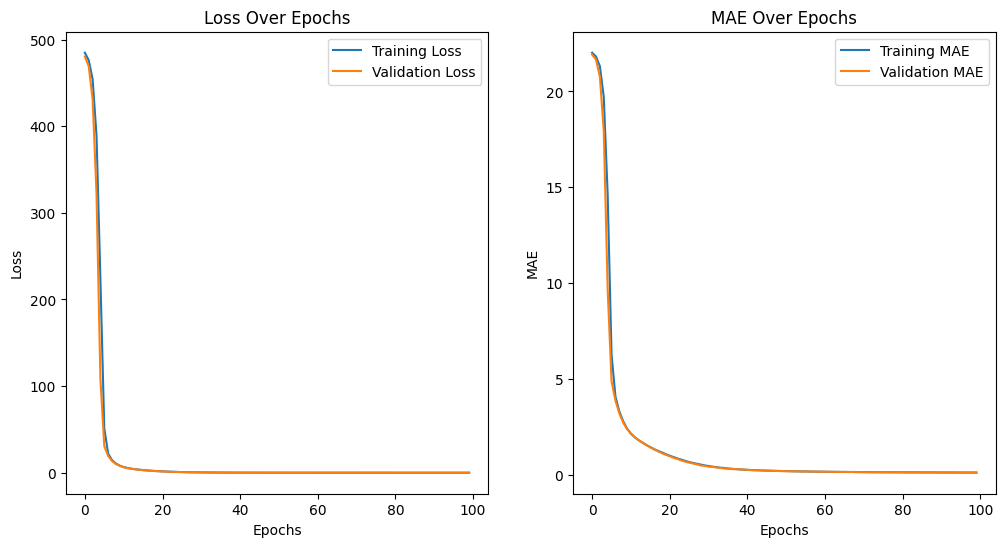

In [11]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(history_v1.history["loss"], label="Training Loss")
plt.plot(history_v1.history["val_loss"], label="Validation Loss")
plt.title("Loss Over Epochs")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_v1.history["mae"], label="Training MAE")
plt.plot(history_v1.history["val_mae"], label="Validation MAE")
plt.title("MAE Over Epochs")
plt.xlabel("Epochs")
plt.ylabel("MAE")
plt.legend()
plt.show()

In [12]:
y_pred_v1 = model_v1.predict(x_test)
test_mse_v1 = mean_squared_error(y_test, y_pred_v1)
test_mae_v1 = mean_absolute_error(y_test, y_pred_v1)
test_rmse_v1 = np.sqrt(test_mse_v1)

print("Model v1 test performance:")
print(f"Test MSE: {test_mse_v1}")
print(f"Test MAE: {test_mae_v1}")
print(f"Test RMSE: {test_rmse_v1}")

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
Model v1 test performance:
Test MSE: 0.02522507913037952
Test MAE: 0.11745740471511587
Test RMSE: 0.15882405085622114


Analisis model v1:
1. **Rapid Initial Learning (Epoch 1-20)**:
    - Loss turun drastis dari 484.78 menjadi 1.82 dalam 20 epoch pertama
    - Ini menunjukkan model dapat dengan cepat mempelajari pola dasar dari data
    - Training dan validation loss bergerak parallel -> indikasi learning sehat
2. **Gradual Refinement (Epoch 20-80)**:
    - Penurunan loss melambat dan menjadi lebih stabil
    - Training loss: 1.82 -> 0.03
    - Validation loss: 1.70 -> 0.02
    - Gap antara training dan validation loss tetap kecil -> indikasi overfitting minimal
3. **Convergence (Epoch 80-100)**:
    - Model mencapai final validation loss 0.0212 (MAE 0.112)
    - Loss curves menunjukkan konvergensi yang stabil
    - Tidak ada tanda-tanda overfitting atau underfitting (validation loss tidak naik)

In [13]:
# Model V2
model_v2 = tf.keras.Sequential([
    tf.keras.layers.Dense(64, activation='relu', input_shape=(x_train.shape[1],)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(1)
])

model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.005),
    loss='mse',
    metrics=['mae']
)

early_stopping_v2 = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history_v2 = model_v2.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping_v2]
)

Epoch 1/100
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 92.8841 - mae: 6.7877 - val_loss: 5.6983 - val_mae: 1.9975
Epoch 2/100
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 3.5740 - mae: 1.4956 - val_loss: 1.6094 - val_mae: 1.0332
Epoch 3/100
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.0927 - mae: 0.7985 - val_loss: 0.5975 - val_mae: 0.5608
Epoch 4/100
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4960 - mae: 0.5199 - val_loss: 0.3715 - val_mae: 0.4564
Epoch 5/100
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3313 - mae: 0.4225 - val_loss: 0.3196 - val_mae: 0.4504
Epoch 6/100
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2546 - mae: 0.3693 - val_loss: 0.1934 - val_mae: 0.3173
Epoch 7/100
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1716 - mae: 0.3036 - val_loss: 0.1391 - val_mae: 0.2663
Epoch 8/100
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1369 - mae: 0.2741 - val_loss: 0.1294 - val_mae: 0.2614
Epoch 9/100
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.11

In [14]:
y_pred_v2 = model_v2.predict(x_test)
test_mse_v2 = mean_squared_error(y_test, y_pred_v2)
test_mae_v2 = mean_absolute_error(y_test, y_pred_v2)
test_rmse_v2 = np.sqrt(test_mse_v2)

print("Model v2:")
print(f"Test MSE:  {test_mse_v2}")
print(f"Test MAE:  {test_mae_v2}")
print(f"Test RMSE: {test_rmse_v2}")

if test_mae_v2 < test_mae_v1:
    improvement = ((test_mae_v1 - test_mae_v2) / test_mae_v1) * 100
    print(f"\n{improvement:.2f}% better than v1")

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
Model v2:
Test MSE:  0.016604234207532306
Test MAE:  0.09883970692118663
Test RMSE: 0.1288574181315624

15.85% better than v1


Model v2:
- Early stopping dengan patience=5 untuk mencegah overfitting
- Batch size 32 untuk stabilitas training
- Hasil: Test MAE 0.0988, improvement 15.85% dari v1
- Observasi: model dengan kapasitas lebih besar dapat menangkap pola yang lebih kompleks

In [15]:
# Model V3
model_v3 = tf.keras.Sequential([
    tf.keras.layers.Dense(64, activation='relu', input_shape=(x_train.shape[1],), kernel_regularizer=regularizers.l2(1e-5)),
    tf.keras.layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2(1e-5)),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(1)
])

model_v3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss='mse',
    metrics=['mae']
)

early_stopping_v3 = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True
)

history_v3 = model_v3.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=16,
    callbacks=[early_stopping_v3]
)

Epoch 1/100
153/153 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 390.4952 - mae: 19.5090 - val_loss: 147.7774 - val_mae: 11.6159
Epoch 2/100
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 30.8972 - mae: 4.3279 - val_loss: 12.2909 - val_mae: 2.8956
Epoch 3/100
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 8.5353 - mae: 2.3209 - val_loss: 6.5313 - val_mae: 2.0768
Epoch 4/100
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 5.2145 - mae: 1.7999 - val_loss: 4.1542 - val_mae: 1.6193
Epoch 5/100
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 3.3532 - mae: 1.4287 - val_loss: 2.6051 - val_mae: 1.2540
Epoch 6/100
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 2.1543 - mae: 1.1280 - val_loss: 1.6812 - val_mae: 0.9838
Epoch 7/100
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.3826 - mae: 0.8998 - val_loss: 1.0723 - val_mae: 0.7892
Epoch 8/100
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.8694 - mae: 0.7020 - val_loss: 0.6875 - val_mae: 0.6135
Epoch 9/100
153/153 ━━━━━━━━━━━━━━━━━━━━

In [16]:
y_pred_v3 = model_v3.predict(x_test)
test_mse_v3 = mean_squared_error(y_test, y_pred_v3)
test_mae_v3 = mean_absolute_error(y_test, y_pred_v3)
test_rmse_v3 = np.sqrt(test_mse_v3)

print("Model v3:")
print(f"Test MSE:  {test_mse_v3}")
print(f"Test MAE:  {test_mae_v3}")
print(f"Test RMSE: {test_rmse_v3}")

if test_mae_v3 < test_mae_v2:
    improvement = ((test_mae_v2 - test_mae_v3) / test_mae_v2) * 100
    print(f"\n{improvement:.2f}% better than v2")

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
Model v3:
Test MSE:  0.012590331408624207
Test MAE:  0.08819627355356686
Test RMSE: 0.11220664600915672

10.77% better than v2


Model v3:
- L2 regularization (1e-5): mencegah overfitting dengan menghukum bobot yang besar
- Lower learning rate (0.0005)L convergence lebih halus dan stabil
- Smaller batch size (16): update gradien lebih sering, noise membantu escape local minima
- Hasil: Test MAE 0.0881, improvement 10.77% dari v2

Metrics yang digunakan:
- MSE (Mean Squared Error): mengukur rata rata kuadrat error
- MAE (Mean Absolute Error): mengukur rata rata absolute error, lebih interpretable
- RMSE (Root Mean Squared Error): same unit dengan target, sensitive to outlier

Best Model: v3
- Architecture: 64->32->16->1 with L2 regularization
- Best hyperparameters:
    - Learning rate: 0.0005
    - Batch size: 16
    - L2 penalty: 1e-5
    - Early stopping patience: 8
- Test Performance:
    - MSE: 0.0126
    - MAE: 0.0882°C
    - RMSE: 0.1122°C

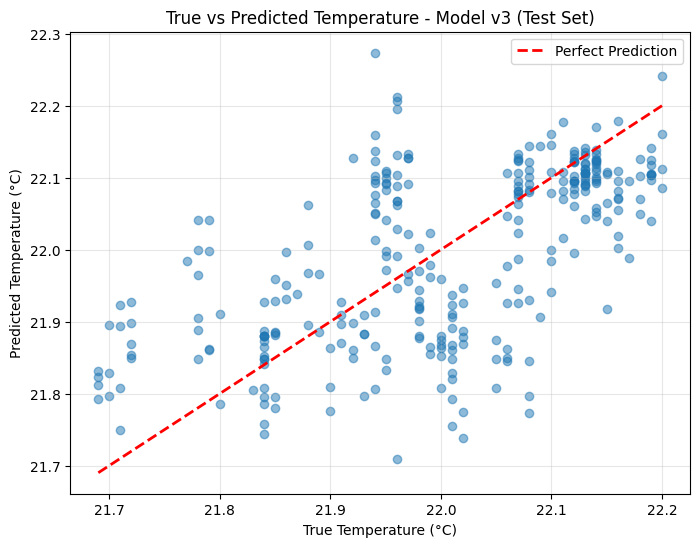

In [17]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_v3, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Prediction')
plt.xlabel('True Temperature (°C)')
plt.ylabel('Predicted Temperature (°C)')
plt.title('True vs Predicted Temperature - Model v3 (Test Set)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Hyperparameter Selection Rationale:
Model v2:
1. Deeper Architecture (64->32->16->8->1):
    - Alasan: menangkap pola yang lebih kompleks dalam data
    - Resiko: potensi overfitting
    - Mitigasi: early stopping patience=5
2. Batch size 32:
    - Alasan: stabilitas training, lebih representatif dari data
    - Efek: konvergensi lebih halus

Model v3:
1. L2 Regularization (1e-5):
    - Alasan: mencegah overfitting dengan menghukum bobot yang besar
    - Choice of 1e-5: cukup kuat untuk regularisasi, cukup lemah untuk tidak menghambat learning
2. Learning rate 0.0005 (vs default 0.001):
    - Alasan: weight updates lebih kecil, convergence lebih halus dan stabil
    - Trade-off: training lebih lambat, tapi hasil akhir lebih baik
3. Batch size 16:
    - Alasan: update gradien lebih sering, noise membantu escape local minima
    - Efek: membantu escape local minima
4. Patience 8:
    - Alasan: memberikan lebih banyak kesempatan untuk improvement sebelum stopping
    - Efek: menghindari premature stopping